# Predicción de aceptación de un depósito a plazo
Aldo Santiago Márquez

Utilizo el conjunto Bank Marketing de Moro et al. (2014), disponible en UCI, para predecir qué clientes aceptarían un depósito a plazo.

In [1]:
import pandas as pd
from pathlib import Path
from urllib.request import urlretrieve
from zipfile import ZipFile

url = "https://archive.ics.uci.edu/ml/machine-learning-databases/00222/bank-additional.zip"
urlretrieve(url, "bank-additional.zip")  # descarga los archivos originales

with ZipFile("bank-additional.zip") as archivo:
    archivo.extractall("datos")

carpeta = Path("datos/bank-additional")
descripcion = (carpeta / "bank-additional-names.txt").read_text(encoding="utf-8-sig")

print(descripcion)

Citation Request:
  This dataset is publicly available for research. The details are described in [Moro et al., 2014]. 
  Please include this citation if you plan to use this database:

  [Moro et al., 2014] S. Moro, P. Cortez and P. Rita. A Data-Driven Approach to Predict the Success of Bank Telemarketing. Decision Support Systems, In press, http://dx.doi.org/10.1016/j.dss.2014.03.001

  Available at: [pdf] http://dx.doi.org/10.1016/j.dss.2014.03.001
                [bib] http://www3.dsi.uminho.pt/pcortez/bib/2014-dss.txt

1. Title: Bank Marketing (with social/economic context)

2. Sources
   Created by: Sérgio Moro (ISCTE-IUL), Paulo Cortez (Univ. Minho) and Paulo Rita (ISCTE-IUL) @ 2014
   
3. Past Usage:

  The full dataset (bank-additional-full.csv) was described and analyzed in:

  S. Moro, P. Cortez and P. Rita. A Data-Driven Approach to Predict the Success of Bank Telemarketing. Decision Support Systems (2014), doi:10.1016/j.dss.2014.03.001.
 
4. Relevant Information:

   This 

Excluí `duration` porque la duración de la llamada todavía no se conoce cuando el banco decide a quién contactar. Usarla introduciría fuga de información y podría mejorar las métricas sin que el modelo fuera útil en ese momento.

In [2]:
df_original = pd.read_csv(carpeta / "bank-additional-full.csv", sep=";")

print("filas y columnas:", df_original.shape)
display(df_original.head())

filas y columnas: (41188, 21)


,age,job,marital,education,default,housing,loan,contact,month,day_of_week,...,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
0,56,housemaid,married,basic.4y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
1,57,services,married,high.school,unknown,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
2,37,services,married,high.school,no,yes,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
3,40,admin.,married,basic.6y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
4,56,services,married,high.school,no,no,yes,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no


In [3]:
df_original = pd.read_csv(carpeta / "bank-additional-full.csv", sep=";")  # carga el archivo completo
df = df_original.drop(columns="duration").copy()  # crea una copia sin la duración

print("dimensiones originales:", df_original.shape)
print("dimensiones sin duration:", df.shape)

dimensiones originales: (41188, 21)
dimensiones sin duration: (41188, 20)


Al eliminar `duration`, se mantienen los 41,188 registros y se pasa de 21 a 20 columnas. De estas, 19 son características que usará el modelo y una es la respuesta que queremos predecir: `y`.


In [4]:
X = df.drop(columns="y")  # características utilizadas para predecir
y = df["y"].map({"no": 0, "yes": 1})  # 0 indica que no aceptó y 1 que sí

print("dimensiones de X:", X.shape)
print("cantidad de respuestas:", y.shape)

dimensiones de X: (41188, 19)
cantidad de respuestas: (41188,)


Separé las características en `X` y la respuesta en `y`, porque el modelo debe predecir la aceptación usando la información del cliente. Codifiqué la respuesta como 0 para “no” y 1 para “sí”.


In [5]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,  # reserva el 20 % para prueba
    random_state=42,  # permite reproducir la misma partición
    stratify=y  # conserva aproximadamente la proporción de ambas clases
)

print("registros de entrenamiento:", len(X_train))
print("registros de prueba:", len(X_test))
print("proporción de positivos en entrenamiento:", y_train.mean())
print("proporción de positivos en prueba:", y_test.mean())

registros de entrenamiento: 32950
registros de prueba: 8238
proporción de positivos en entrenamiento: 0.11265553869499241
proporción de positivos en prueba: 0.11264870114105366


Reservé el 20 % de los registros para evaluar el modelo con datos que no se utilizaron durante el entrenamiento. La partición estratificada mantuvo aproximadamente un 11.27 % de aceptaciones en ambos conjuntos, por lo que conservan una proporción de clases similar.

In [6]:
from sklearn.metrics import accuracy_score

pred_siempre_no = [0] * len(y_test)  # predice que ningún cliente acepta
exactitud_base = accuracy_score(y_test, pred_siempre_no)

print(f"exactitud de predecir siempre no: {exactitud_base:.2%}")

exactitud de predecir siempre no: 88.74%


Como la mayoría de los clientes no acepta, predecir siempre “no” puede dar una exactitud alta sin identificar ninguna aceptación. Por eso, la exactitud por sí sola no basta para evaluar si el modelo ayuda al banco a elegir a quién llamar.

In [7]:
numericas = X_train.select_dtypes(include="number").columns.tolist()  # columnas numéricas
categoricas = X_train.select_dtypes(exclude="number").columns.tolist()  # columnas categóricas

print("variables numéricas:", numericas)
print("variables categóricas:", categoricas)

variables numéricas: ['age', 'campaign', 'pdays', 'previous', 'emp.var.rate', 'cons.price.idx', 'cons.conf.idx', 'euribor3m', 'nr.employed']
variables categóricas: ['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'day_of_week', 'poutcome']


Separé las variables numéricas de las categóricas porque necesitan tratamientos diferentes. Para las categóricas usaré one-hot, que representa cada categoría con una columna indicadora sin imponer un orden artificial entre ellas.

In [8]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

preprocesamiento = ColumnTransformer(
    transformers=[
        ("numericas", StandardScaler(), numericas),  # estandariza las variables numéricas
        ("categoricas", OneHotEncoder(handle_unknown="ignore"), categoricas)  # convierte categorías en indicadores
    ]
)

Definí un preprocesamiento que estandariza las variables numéricas y aplica one-hot a las categóricas. Estas transformaciones se integrarán con la regresión logística en un Pipeline para aplicar el mismo procedimiento durante el entrenamiento y la predicción.

Las medias y desviaciones del escalado deben calcularse únicamente con los datos de entrenamiento. Después se aplican esos mismos valores al conjunto de prueba, evitando que este influya en el ajuste.


In [10]:
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression

modelo = Pipeline([
    ("preprocesamiento", preprocesamiento),  # prepara las variables
    ("regresion", LogisticRegression(max_iter=2000))  # establece el máximo de iteraciones del ajuste
])

modelo.fit(X_train, y_train)  # ajusta las transformaciones y la regresión con entrenamiento

Pipeline(steps=[('preprocesamiento',
                 ColumnTransformer(transformers=[('numericas', StandardScaler(),
                                                  ['age', 'campaign', 'pdays',
                                                   'previous', 'emp.var.rate',
                                                   'cons.price.idx',
                                                   'cons.conf.idx', 'euribor3m',
                                                   'nr.employed']),
                                                 ('categoricas',
                                                  OneHotEncoder(handle_unknown='ignore'),
                                                  ['job', 'marital',
                                                   'education', 'default',
                                                   'housing', 'loan', 'contact',
                                                   'month', 'day_of_week',
                                                   'poutcome'])])),
                ('regresion', LogisticRegression(max_iter=2000))])

Para predecir clientes nuevos se conservan las medias y desviaciones calculadas durante el entrenamiento. El Pipeline aplica esa misma transformación automáticamente, manteniendo la representación con la que aprendió la regresión.

El escalado expresa qué tan lejos está cada valor de la media del entrenamiento, en unidades de desviación estándar. Por ejemplo, una edad de 60 años se transforma en 2 si la media es 40 y la desviación es 10.

In [11]:
probabilidades = modelo.predict_proba(X_test)[:, 1]  # probabilidad estimada de aceptar
pred_05 = (probabilidades >= 0.5).astype(int)  # convierte las probabilidades en decisiones

display(pd.DataFrame({
    "probabilidad de aceptar": probabilidades[:10],
    "predicción": pred_05[:10],
    "respuesta real": y_test.iloc[:10].to_numpy()
}))

,probabilidad de aceptar,predicción,respuesta real
0,0.068581,0,0
1,0.480007,0,0
2,0.562893,1,0
3,0.044166,0,0
4,0.414955,0,0
5,0.264988,0,0
6,0.066952,0,0
7,0.055851,0,0
8,0.561494,1,1
9,0.052827,0,0


Convertí las probabilidades estimadas en predicciones usando un umbral de 0.5: valores mayores o iguales se clasifican como “sí” y el resto como “no”. Una predicción negativa no significa que el cliente no pueda aceptar, sino que su probabilidad estimada quedó debajo del umbral.

In [12]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, pred_05, labels=[0, 1])  # cuenta aciertos y errores por clase

display(pd.DataFrame(
    cm,
    index=["real: no", "real: sí"],
    columns=["predicción: no", "predicción: sí"]
))

,predicción: no,predicción: sí
real: no,7219,91
real: sí,725,203


Con el umbral de 0.5, el modelo identifica correctamente 203 aceptaciones, pero deja sin detectar otras 725. Aunque acierta en muchos clientes que no aceptan, necesitamos calcular las métricas para evaluar qué tan bien identifica a quienes sí aceptan.

In [13]:
vn, fp, fn, vp = cm.ravel()  # extrae los cuatro conteos de la matriz

metricas = {
    "exactitud": (vp + vn) / (vn + fp + fn + vp),  # aciertos entre todos los registros
    "precisión": vp / (vp + fp),  # aceptaciones reales entre los sí predichos
    "sensibilidad": vp / (vp + fn),  # aceptaciones detectadas entre todas las reales
    "especificidad": vn / (vn + fp),  # negativos detectados entre todos los reales
    "f1": 2 * vp / (2 * vp + fp + fn)  # media armónica de precisión y sensibilidad
}

for nombre, valor in metricas.items():
    print(f"{nombre}: {valor:.2%}")

exactitud: 90.09%
precisión: 69.05%
sensibilidad: 21.88%
especificidad: 98.76%
f1: 33.22%


Con el umbral de 0.5, el modelo obtiene 90.09 % de exactitud y 98.76 % de especificidad, pero su sensibilidad de 21.88 % indica que deja escapar la mayoría de las aceptaciones. La precisión de 69.05 % muestra que suele acertar cuando predice “sí”, mientras que el F1 de 33.22 % refleja su baja cobertura de los positivos. Para el banco es especialmente importante la sensibilidad, porque permite encontrar más clientes que aceptarían, aunque debe equilibrarse con la precisión y el costo de las llamadas.

La precisión y la sensibilidad utilizan los mismos verdaderos positivos, pero distintos denominadores. La precisión evalúa qué proporción de los positivos predichos fue correcta, mientras que la sensibilidad evalúa qué proporción de los positivos reales logró detectar el modelo.

La sensibilidad baja muestra que el modelo deja sin detectar muchas aceptaciones con el umbral de 0.5. Para explorar su comportamiento con otros umbrales, revisaré las curvas ROC y de precisión contra sensibilidad.

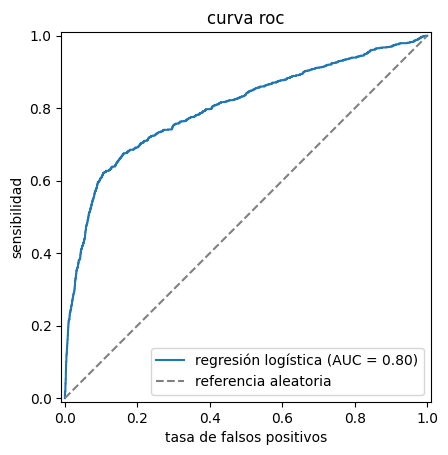

In [14]:
import matplotlib.pyplot as plt
from sklearn.metrics import RocCurveDisplay

RocCurveDisplay.from_predictions(
    y_test,
    probabilidades,  # utiliza probabilidades para evaluar distintos umbrales
    name="regresión logística"
)

plt.plot([0, 1], [0, 1], "--", color="gray", label="referencia aleatoria")
plt.xlabel("tasa de falsos positivos")
plt.ylabel("sensibilidad")
plt.title("curva roc")
plt.legend()
plt.show()

La curva ROC obtiene un AUC de aproximadamente 0.80, lo que indica que el modelo tiene capacidad para distinguir entre ambas clases al variar el umbral. Sin embargo, esta curva no muestra directamente qué proporción de los clientes seleccionados realmente acepta, algo importante porque los positivos son pocos.

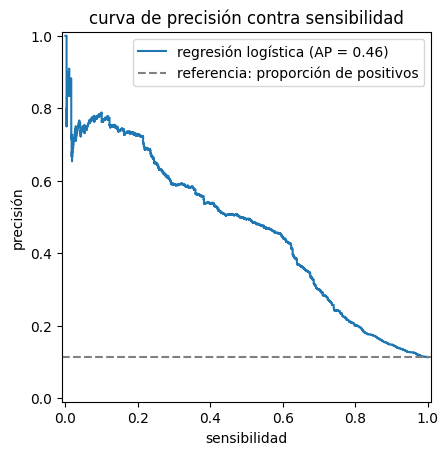

precisión promedio: 0.4648


In [15]:
from sklearn.metrics import PrecisionRecallDisplay, average_precision_score

ap = average_precision_score(y_test, probabilidades)  # resume la curva mediante precisión promedio

PrecisionRecallDisplay.from_predictions(
    y_test,
    probabilidades,
    name="regresión logística"
)

plt.axhline(y_test.mean(), linestyle="--", color="gray",
            label="referencia: proporción de positivos")
plt.xlabel("sensibilidad")
plt.ylabel("precisión")
plt.title("curva de precisión contra sensibilidad")
plt.legend()
plt.show()

print(f"precisión promedio: {ap:.4f}")

La curva de precisión contra sensibilidad obtiene una precisión promedio de 0.4648, superior a la referencia de aproximadamente 0.1127. Al aumentar la sensibilidad, la precisión tiende a disminuir, mostrando que recuperar más aceptaciones también implica seleccionar a más clientes que no aceptan. Esto se aprecia menos directamente en la curva ROC, donde muchos falsos positivos pueden representar una tasa pequeña al dividirse entre una gran cantidad de negativos.

In [16]:
costo_llamada = 5
ingreso_aceptacion = 50

umbral_economico = costo_llamada / ingreso_aceptacion  # probabilidad de equilibrio
print(f"umbral económico: {umbral_economico:.0%}")

umbral económico: 10%


La ganancia esperada de una llamada es 50p − 5, donde p es la probabilidad de aceptación. Por eso conviene llamar cuando esa probabilidad supera el 10 %; este umbral se obtiene de los costos e ingresos del problema, sin elegirlo con los resultados de prueba.

In [17]:
resultados = []

for umbral in [0.5, umbral_economico]:
    llamar = probabilidades >= umbral  # selecciona a quién llamar
    llamadas = llamar.sum()
    aceptaciones = (llamar & (y_test.to_numpy() == 1)).sum()  # seleccionados que realmente aceptaron

    ingresos = aceptaciones * ingreso_aceptacion
    costos = llamadas * costo_llamada  # todas las llamadas cuestan
    ganancia = ingresos - costos

    resultados.append({
        "umbral": umbral,
        "llamadas": llamadas,
        "aceptaciones": aceptaciones,
        "ingresos": ingresos,
        "costos": costos,
        "ganancia": ganancia
    })

comparacion = pd.DataFrame(resultados)
display(comparacion)

,umbral,llamadas,aceptaciones,ingresos,costos,ganancia
0,0.5,294,203,10150,1470,8680
1,0.1,1900,632,31600,9500,22100


Comparo los umbrales de 0.5 y 0.1 calculando los ingresos por las aceptaciones detectadas y restando el costo de todas las llamadas seleccionadas. Esto permite evaluar si contactar a más clientes mejora la ganancia total, aunque disminuya la precisión.

Con el umbral de 0.5 se realizan 294 llamadas, se consiguen 203 aceptaciones y la ganancia es de 8,680 unidades monetarias. Con el umbral económico de 0.1 se realizan 1,900 llamadas, se consiguen 632 aceptaciones y la ganancia aumenta a 22,100. En este conjunto de prueba, contactar a más clientes resulta rentable porque los ingresos adicionales superan el aumento en los costos.

Aceptar una menor precisión puede permitir encontrar suficientes clientes adicionales para ganar más. El matiz es que necesitamos volumen rentable: llamar a más personas también puede generar pérdidas si las aceptaciones adicionales no compensan los costos.

In [18]:
X_train_duration = X_train.copy()
X_test_duration = X_test.copy()

X_train_duration["duration"] = df_original.loc[X_train.index, "duration"]  # recupera la duración de cada registro
X_test_duration["duration"] = df_original.loc[X_test.index, "duration"]

print("variables sin duration:", X_train.shape[1])
print("variables con duration:", X_train_duration.shape[1])

variables sin duration: 19
variables con duration: 20


Agregué `duration` únicamente para realizar la comparación solicitada y observar cómo cambia la evaluación. Conservé los mismos registros de entrenamiento y prueba para comparar ambos modelos bajo las mismas condiciones.

Mantengo la misma partición para que la comparación no dependa de un cambio en los clientes evaluados. Así, la diferencia entre los modelos será la inclusión de `duration`, conservando el mismo procedimiento de entrenamiento.

In [19]:
preprocesamiento_duration = ColumnTransformer([
    ("numericas", StandardScaler(), numericas + ["duration"]),  # incluye la duración entre las numéricas
    ("categoricas", OneHotEncoder(handle_unknown="ignore"), categoricas)
])

modelo_duration = Pipeline([
    ("preprocesamiento", preprocesamiento_duration),
    ("regresion", LogisticRegression(max_iter=2000))
])

modelo_duration.fit(X_train_duration, y_train)  # entrena el modelo de comparación

Pipeline(steps=[('preprocesamiento',
                 ColumnTransformer(transformers=[('numericas', StandardScaler(),
                                                  ['age', 'campaign', 'pdays',
                                                   'previous', 'emp.var.rate',
                                                   'cons.price.idx',
                                                   'cons.conf.idx', 'euribor3m',
                                                   'nr.employed', 'duration']),
                                                 ('categoricas',
                                                  OneHotEncoder(handle_unknown='ignore'),
                                                  ['job', 'marital',
                                                   'education', 'default',
                                                   'housing', 'loan', 'contact',
                                                   'month', 'day_of_week',
                                                   'poutcome'])])),
                ('regresion', LogisticRegression(max_iter=2000))])

Incluir `duration` no resuelve el problema práctico del banco, porque esa información no está disponible al decidir a quién contactar. Esta comparación permite observar cuánto pueden mejorar las métricas al utilizar información que no tendríamos en ese momento.

In [20]:
prob_duration = modelo_duration.predict_proba(X_test_duration)[:, 1]
pred_duration = (prob_duration >= 0.5).astype(int)  # conserva el umbral de la primera evaluación

cm_duration = confusion_matrix(y_test, pred_duration, labels=[0, 1])
vn_d, fp_d, fn_d, vp_d = cm_duration.ravel()  # conteos del modelo con duración

display(pd.DataFrame(
    cm_duration,
    index=["real: no", "real: sí"],
    columns=["predicción: no", "predicción: sí"]
))

metricas_duration = {
    "exactitud": (vp_d + vn_d) / cm_duration.sum(),
    "precisión": vp_d / (vp_d + fp_d),
    "sensibilidad": vp_d / (vp_d + fn_d),
    "especificidad": vn_d / (vn_d + fp_d),
    "f1": 2 * vp_d / (2 * vp_d + fp_d + fn_d)
}

comparacion_metricas = pd.DataFrame({
    "sin duration": metricas,
    "con duration": metricas_duration
})

display(comparacion_metricas.style.format("{:.2%}"))

,predicción: no,predicción: sí
real: no,7146,164
real: sí,523,405


,sin duration,con duration
exactitud,90.09%,91.66%
precisión,69.05%,71.18%
sensibilidad,21.88%,43.64%
especificidad,98.76%,97.76%
f1,33.22%,54.11%


Al incluir `duration`, la sensibilidad aumenta de 21.88 % a 43.64 % y el F1 pasa de 33.22 % a 54.11 %, por lo que el modelo detecta más aceptaciones. También mejoran la exactitud y la precisión, aunque la especificidad disminuye porque aparecen más falsos positivos. Estas mejoras no servirían para decidir a quién llamar, ya que la duración solo se conoce después de realizar la llamada y su inclusión introduce fuga de información.

Como conclusión, elegiría la regresión logística sin `duration`, porque permite predecir sin utilizar la duración de una llamada que todavía no se realiza. Con los costos e ingresos del ejercicio, usaría el umbral de 0.1, que en prueba aumentó la ganancia de 8,680 a 22,100 unidades monetarias. Aunque disminuye la precisión, recupera suficientes aceptaciones adicionales para compensar las llamadas que no terminan en una aceptación.

Como idea adicional a la tarea, desde mi consultora propondría al banco una segunda etapa: desarrollar un sistema de análisis de conversaciones que conecte la selección de clientes con la efectividad de las llamadas. El modelo actual permitiría priorizar a quién contactar; el siguiente paso sería investigar qué ocurre durante la conversación y qué oportunidades existen para mejorar la campaña.

Para ello, propondría analizar grabaciones y transcripciones, separando cada llamada en presentación, explicación del producto, preguntas, objeciones y cierre. Buscaría identificar qué argumentos despiertan interés, dónde aparecen dudas y qué patrones se relacionan con una aceptación. En esa etapa exploraría `duration` como una señal para analizar llamadas ya realizadas: una conversación larga podría representar una oportunidad comercial, pero también una explicación poco clara.

Con esos hallazgos diseñaría versiones alternativas del guion y las evaluaría mediante pruebas controladas. Mediría su efecto sobre la aceptación, el tiempo invertido y la ganancia por cliente contactado, para comprobar cuáles mejoras producen resultados.

La propuesta sería construir un ciclo de aprendizaje: seleccionar clientes, analizar conversaciones, probar cambios y actualizar la estrategia con evidencia. Así, el banco podría transformar sus llamadas en una fuente de conocimiento para mejorar tanto la asignación de recursos como la calidad de sus conversaciones comerciales. :)